# MinVola: Problem-specific Heuristic, AI, dan komputasi kuantum

**Notebook belajar dan eksperimen yang dapat dijalankan ulang.** Referensi: Stopfer & Wagner, *Quantum Portfolio Optimization: An Extensive Benchmark*, arXiv:2509.17876v3, Appendix A/C. https://arxiv.org/abs/2509.17876

Portofolio berarti pembagian dana ke beberapa aset. Bobot 0.4 berarti 40% dana. Tujuan MinVola: risiko varians serendah mungkin, return minimal tercapai, bobot sum=1 dan tidak melewati cap.

Replikasi ini menggunakan formulasi dan prinsip heuristik paper. Dataset, perangkat, solver dan budget tidak identik; lihat `docs/REPLICATION.md`. Quantum di sini simulator klasik ideal. AI adalah tambahan eksperimen, tidak ada pada paper.

In [1]:
from pathlib import Path
import sys, json, time
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'psh').is_dir())
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from psh.data import synthetic, read_csv, statistics, chronological_split, fingerprint
from psh.heuristic import Problem, paper_bounds, heuristic, continuous_solver, metrics
from psh.qubo import build_qubo, sample_qubo, postprocess, exact_grid, qaoa_statevector, bitstrings
from psh.ai import fit_surrogate, predict, complement
from psh.experiment import run_experiment
SEED = 42
plt.rcParams.update({'figure.figsize':(10,4), 'axes.grid':True})

## 1. Pilih data
Demo sintetis selalu dapat berjalan offline. Untuk data nyata, jalankan `python -m scripts.download_data --source french` atau `--source yahoo`, lalu ubah DATA_PATH. French berisi return portofolio industri, bukan harga saham; Yahoo lebih dekat dengan sumber paper. Jangan menyebut hasil demo sebagai bukti investasi.

CSV `date,ASSET_A,ASSET_B,...`, daily return desimal. Tidak mengisi missing data secara diam-diam.

Shape: (756, 6) SHA256: be2c3e9c5e2402d7608b893c56446f62dbc5887dd2e16d5bc72b3477c9859085


,ASSET_01,ASSET_02,ASSET_03,ASSET_04,ASSET_05,ASSET_06
2020-01-01,0.007213,0.012824,0.010124,-0.011157,0.002663,0.008937
2020-01-02,0.006910,-0.009742,0.002231,0.007548,0.013487,-0.013206
2020-01-03,-0.003294,-0.002978,-0.003228,-0.005747,-0.019296,-0.003017
2020-01-06,0.003104,-0.001953,0.018233,0.000785,0.011804,0.007705
2020-01-07,0.007218,0.008913,0.011466,0.000028,0.007433,0.006777


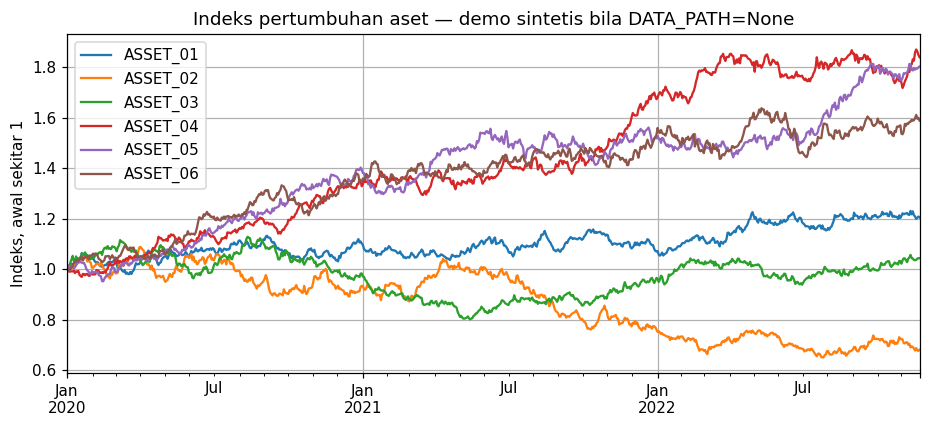

In [2]:
DATA_PATH = None # contoh: root/'data/market/returns.csv'
returns = synthetic(n=6, days=756, seed=SEED) if DATA_PATH is None else read_csv(DATA_PATH)
# Untuk API pilih <=12 aset. Notebook klasik bisa lebih; simulator quantum punya batas tersendiri.
display(returns.head())
print('Shape:', returns.shape, 'SHA256:', fingerprint(returns))
(1+returns).cumprod().plot(title='Indeks pertumbuhan aset — demo sintetis bila DATA_PATH=None')
plt.ylabel('Indeks, awal sekitar 1'); plt.show()

## 2. Pisahkan waktu sebelum belajar
Train 60%, validation 20%, test 20%. Model AI hanya fit train dan pilih parameter pada validation. Statistik untuk menentukan alokasi final memakai seluruh history **sebelum test**, setelah model dipilih. Test tidak masuk estimasi return/kovarians atau tuning.

Ini ekstensi evaluasi di luar periode pengembangan; paper benchmark mengoptimasi masalah statis, bukan backtest trading.

In [3]:
train, val, test = chronological_split(returns)
history = returns.iloc[:len(train)+len(val)]
assert train.index.max() < val.index.min() and val.index.max() < test.index.min()
display(pd.DataFrame([{'split':name,'start':str(x.index[0].date()),'end':str(x.index[-1].date()),'rows':len(x)}
 for name,x in [('train',train),('validation',val),('test',test)]]))

,split,start,end,rows
0,train,2020-01-01,2021-09-24,453
1,validation,2021-09-27,2022-04-25,151
2,test,2022-04-26,2022-11-23,152


## 3. Ubah deret waktu menjadi masukan optimasi
Paper Appendix A:

$$r_{i,t}=p_{i,t}/p_{i,t-1}-1,\quad \mu_i=\left[\prod_t(1+r_{i,t})\right]^{252/T}-1$$

$$\Sigma=\frac{252}{T}(R-\bar R)^\mathsf{T}(R-\bar R).$$

Di sini T adalah jumlah return, covariance memakai ddof=0. Target epsilon adalah quantile 70% mu, cap u=max(0.1,3/n). Semua satuan return tahunan desimal. Pada 6 aset, cap 0.5. Parameter paper d=3 sehingga delta=u/8.

epsilon= 0.19548317930353862 delta= 0.0625


,asset,annual_geometric_return,upper_bound
0,ASSET_01,0.072430,0.5
1,ASSET_02,-0.112944,0.5
2,ASSET_03,0.007102,0.5
3,ASSET_04,0.288079,0.5
4,ASSET_05,0.185211,0.5
5,ASSET_06,0.205755,0.5


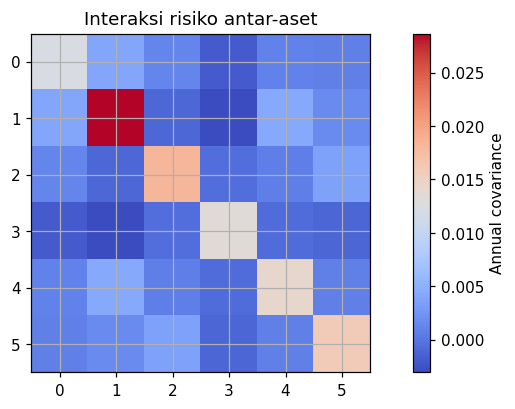

In [4]:
mu, cov = statistics(history)
ub = paper_bounds(len(mu))
epsilon = float(np.quantile(mu, 0.7))
p = Problem(mu, cov, ub, epsilon)
D_PAPER = 3
delta = float(ub[0]/2**D_PAPER)
display(pd.DataFrame({'asset':returns.columns,'annual_geometric_return':mu,'upper_bound':ub}))
print('epsilon=',epsilon,'delta=',delta)
plt.imshow(cov,cmap='coolwarm'); plt.colorbar(label='Annual covariance'); plt.title('Interaksi risiko antar-aset'); plt.show()

## 4. Heuristik khusus masalah — langkah demi langkah
Untuk setiap aset awal: beri delta, lalu coba tambahan delta ke semua aset. Jika ada kandidat memenuhi target, pilih varians terkecil; jika belum, pilih return tertinggi. Ulangi sampai sum(x) >= 1−delta/2, normalkan, cek kelayakan.

**Pemeriksaan PDF visual:** stop condition adalah 1−delta/2, bukan 1−2delta; ekstraksi teks merusak pecahan. Line 50 mengalikan dengan total bobot, tampaknya typo. Default corrected membagi dengan total bobot; literal mempertahankan perkalian untuk audit. Tidak ada jaminan optimum global, dan hasil normalisasi dapat melanggar cap.

In [5]:
h = heuristic(p,delta=delta,mode='corrected')
literal = heuristic(p,delta=delta,mode='literal')
display(pd.DataFrame([{k:c[k] for k in ['start','feasible','expected_return','variance','capacity_exhausted']} for c in h['candidates']]))
print('Feasible start fraction:',h['feasible_fraction'])
if h['best']:
    display(pd.DataFrame(h['best']['trace']).head(12))
    display(pd.DataFrame({'asset':returns.columns,'weight':h['best']['weights']}))
else: print('Tidak ada kandidat layak: periksa target, cap dan delta.')

Feasible start fraction: 1.0


,start,feasible,expected_return,variance,capacity_exhausted
0,0,True,0.201347,0.003349,False
1,1,True,0.203239,0.003684,False
2,2,True,0.197264,0.003335,False
3,3,True,0.201347,0.003349,False
4,4,True,0.201347,0.003349,False
5,5,True,0.201347,0.003349,False


,step,asset_index,sum,decision
0,1,3,0.1250,max_return_fallback
1,2,3,0.1875,max_return_fallback
2,3,5,0.2500,min_variance
3,4,5,0.3125,min_variance
4,5,4,0.3750,min_variance
5,6,3,0.4375,min_variance
6,7,4,0.5000,min_variance
7,8,4,0.5625,min_variance
8,9,3,0.6250,min_variance
9,10,0,0.6875,min_variance


,asset,weight
0,ASSET_01,0.1250
1,ASSET_02,0.0000
2,ASSET_03,0.0625
3,ASSET_04,0.3125
4,ASSET_05,0.2500
5,ASSET_06,0.2500


In [6]:
# Contoh delta non-divisor menunjukkan beda literal dan corrected secara jelas.
toy = Problem([.05,.1,.2],np.diag([.01,.02,.04]),np.ones(3),0.)
for mode in ['literal','corrected']:
    example=heuristic(toy,delta=.3,mode=mode)
    print(mode, 'total weights=',sum(example['candidates'][0]['weights']), 'feasible=',example['candidates'][0]['feasible'])

literal total weights= 0.8099999999999998 feasible= False
corrected total weights= 1.0 feasible= True


## 5. Solver klasik kontinu sebagai acuan
SLSQP menyelesaikan formulasi kontinu dengan constraint asli. Ini referensi numerik, bukan sertifikat optimum diskret Gurobi yang dipakai paper. Bandingkan hanya hasil yang feasible; varians lebih kecil pada hasil yang melanggar target tidak berarti lebih baik.

In [7]:
reference=continuous_solver(p)
display(reference)
if h['best'] and reference.get('feasible'):
    print('Variance heuristic / continuous reference:',h['best']['variance']/reference['variance'])

Variance heuristic / continuous reference: 1.058385482440725


{'weights': [0.2005490230864983,
  0.0,
  0.041278601254793774,
  0.35124272543489443,
  0.2068320005159238,
  0.20009764970788976],
 'expected_return': 0.1954831793035386,
 'variance': 0.003150870066505888,
 'volatility': 0.05613261143493939,
 'feasible': True,
 'violations': {'sum': 0.0,
  'lower': 0.0,
  'upper': 0.0,
  'return': 2.7755575615628914e-17},
 'solver_success': True,
 'message': 'Optimization terminated successfully'}

## 6. QUBO: format bersama untuk algoritma sampling
Objektif paper: variance + 1000(return−(epsilon+0.01))² + 1000(sum(weights)−1)². Return inequality diganti penalti equality; ini perubahan model, bukan transformasi yang selalu setara.

Encoding memakai d+1 bit/aset. d=3 berarti 4 bit/aset. Bitstring diterjemahkan menjadi bobot dengan cap bawaan. Sesudah sampling, ambil 100 energy terendah, normalkan dan cek constraint kembali. Normalisasi bisa mengubah grid/batas.

Di demo utama kita pakai d=1 untuk enumerasi kecil, dan di bagian quantum pakai d=3 pada tiga aset. Tidak membandingkan ratio ke optimum grid bila bobot sudah keluar grid.

In [8]:
Q,B,offset=build_qubo(p,d=1)
bits=bitstrings(len(Q))
# Identity test: QUBO dan objective paper harus sama, termasuk constant offset.
b=bits[len(bits)//3]; w=B@b
objective=w@cov@w+1000*(w@mu-epsilon-.01)**2+1000*(w.sum()-1)**2
assert np.isclose(b@Q@b+offset,objective)
print('Variables=',len(Q),'offset=',offset)
sampling=[]
for method in ['random','sa','steepest','tabu']:
    samples, timing=sample_qubo(Q,method,reads=100,sweeps=100,seed=SEED)
    result=postprocess(samples,Q,B,p)
    best=result['best']
    sampling.append({'method':method,'feasible':best is not None,'variance':None if best is None else best['variance'],
                     'runtime_seconds':timing['runtime_seconds'],'candidate_feasible_fraction':result['feasible_fraction']})
display(pd.DataFrame(sampling))
if B.shape[1]<=16: display(exact_grid(p,B))

Variables= 12 offset= 1042.2233369766902


,method,feasible,variance,runtime_seconds,candidate_feasible_fraction
0,random,True,0.003409,0.000802,0.01
1,sa,True,0.004395,0.089693,0.20
2,steepest,True,0.004395,0.004775,0.41
3,tabu,True,0.004395,0.150632,1.00


{'weights': [0.25, 0.0, 0.0, 0.5, 0.0, 0.25],
 'expected_return': 0.21358561160505982,
 'variance': 0.004395263369096781,
 'volatility': 0.06629678249430195,
 'feasible': True,
 'violations': {'sum': 0.0, 'lower': 0.0, 'upper': 0.0, 'return': 0.0},
 'message': 'Exhaustive grid optimum'}

## 7. AI sebagai pembanding dan pelengkap
Random Forest supervised mempelajari pemetaan statistik → bobot. Label diperoleh dari solver kontinu pada rolling historical windows; ia **meniru alokasi solver**, tidak memprediksi keuntungan masa depan.

Validation memilih max_depth 4 atau 8 dari MAE bobot. Prediksi diproyeksikan agar sum=1 dan memenuhi cap, tetapi target return tetap diperiksa. Hybrid memakai prediksi sebagai warm start solver dan membandingkan dengan heuristic. Manfaat solver tidak boleh disebut sebagai manfaat AI saja.

Model terbatas pada urutan aset, fitur dan versi yang sama. Simpan model beserta metadata; jangan memuat file joblib dari sumber tak dipercaya.

In [9]:
model, ai_meta=fit_surrogate(train,val,ub,seed=SEED)
ai_result=predict(model,p)
hybrid=complement(model,p,h)
display(ai_meta)
display(pd.DataFrame([{'method':name,**{k:r.get(k) for k in ['feasible','expected_return','variance','selected_source']}}
                      for name,r in [('ai',ai_result),('hybrid',hybrid)]]))
import joblib
artifacts=root/'artifacts'; artifacts.mkdir(exist_ok=True)
joblib.dump(model,artifacts/'allocation_surrogate.joblib')
(artifacts/'model_metadata.json').write_text(json.dumps({'assets':list(returns.columns),'seed':SEED,
 'dataset_sha256':fingerprint(returns),'training':ai_meta,'scope':'Allocation surrogate; no return forecast'},indent=2))

Out[0]: 

{'training_labels': 81,
 'validation_labels': 21,
 'validation_weight_mae': 0.060403139248716174,
 'trials': [{'max_depth': 4, 'validation_weight_mae': 0.06154072090407773},
  {'max_depth': 8, 'validation_weight_mae': 0.060403139248716174}],
 'train_last_label_date': '2021-09-21',
 'validation_last_label_date': '2022-04-22',
 'teacher': 'continuous SLSQP; solver success and feasible labels only',
 'meaning': 'MAE measures imitation of teacher, not future profitability'}

,method,feasible,expected_return,variance,selected_source
0,ai,False,0.163209,0.003069,None
1,hybrid,True,0.195483,0.003151,ai_warmstart_slsqp


856

## 8. Quantum: QAOA simulator pada formulasi paper d=3
Gunakan tiga aset agar 12 qubit. Ini simulator statevector yang dijalankan komputer **klasik**, bukan hardware kuantum. QAOA terdiri atas superposisi awal, fase dari biaya QUBO, lalu X mixer, diulang p kali. LR memakai formula paper; COBYLA dimulai dari LR. Grid kecil p=1 memakai evaluasi statevector, bukan rumus analytic paper.

Parameter/iterasi/shots berbeda dari benchmark paper; tidak menyimpulkan quantum advantage. Hardware D-Wave opsional ada di `psh/quantum.py` dan tidak dipanggil otomatis.

In [10]:
small=history.iloc[:,:3]
smu,scov=statistics(small)
sp=Problem(smu,scov,paper_bounds(3),float(np.quantile(smu,.7)))
sQ,sB,soffset=build_qubo(sp,d=3)
quantum=[]
for strategy in ['lr','cobyla','grid']:
    samples,meta=qaoa_statevector(sQ,layers=1,shots=512,maxiter=30,parameters=strategy,seed=SEED)
    result=postprocess(samples,sQ,sB,sp)
    quantum.append({'strategy':strategy,'feasible':result['best'] is not None,
                    'variance':None if result['best'] is None else result['best']['variance'],
                    'runtime_seconds':meta['runtime_seconds'],'qubits':meta['qubits']})
display(pd.DataFrame(quantum))
display(exact_grid(sp,sB))

,strategy,feasible,variance,runtime_seconds,qubits
0,lr,True,0.007191,0.000849,12
1,cobyla,True,0.007593,0.027648,12
2,grid,True,0.007593,0.013646,12


{'weights': [0.625, 0.0, 0.375],
 'expected_return': 0.04793205377633586,
 'variance': 0.007914767165421334,
 'volatility': 0.08896497718440294,
 'feasible': True,
 'violations': {'sum': 0.0, 'lower': 0.0, 'upper': 0.0, 'return': 0.0},
 'message': 'Exhaustive grid optimum'}

Sirkuit Qiskit opsional (install extra quantum terlebih dahulu):

```python
from psh.quantum import qiskit_circuit
qc = qiskit_circuit(sQ, [1.2, 0.0], layers=1)
print(qc)
```

Belum ada IBM Runtime submission workflow terintegrasi. Jangan menyamakan simulasi sirkuit dengan eksekusi QPU.

## 9. Perbandingan terpadu dan evaluasi test
Semua algoritma optimasi di sini memakai **mu, covariance, target, bounds yang sama** dalam satu run. AI memperkirakan bobot untuk problem yang sama.

Ukuran: feasibility, variance, waktu, training cost, realized annual return/volatility/drawdown pada test. Test memakai bobot statis dengan daily rebalancing tanpa biaya; interpretasinya terbatas. Demo memiliki budget reads/steps berbeda antar-metode, bukan fixed device-time 60 s paper.

{'train': ['2020-01-01', '2021-09-24'], 'validation': ['2021-09-27', '2022-04-25'], 'test': ['2022-04-26', '2022-11-23']} Method-specific budgets differ; training included separately; not paper fixed-time benchmark


,method,feasible,expected_return,variance,runtime_seconds,training_seconds
0,problem_specific_heuristic,True,0.213586,0.004395,0.000603,NaN
1,continuous_slsqp,True,0.195483,0.003151,0.002444,NaN
2,equal_weight,False,0.107606,0.003384,0.000000,NaN
3,ai_surrogate,False,0.163209,0.003069,0.005046,0.388782
4,ai_complement_heuristic,True,0.195483,0.003151,0.009687,0.388782
5,qubo_random,True,0.207911,0.003409,0.004402,NaN
6,qubo_sa,True,0.213586,0.004395,0.114228,NaN
7,qubo_steepest,True,0.213586,0.004395,0.006218,NaN
8,qubo_tabu,True,0.213586,0.004395,0.176765,NaN
9,exact_discrete_grid,True,0.213586,0.004395,0.000396,NaN


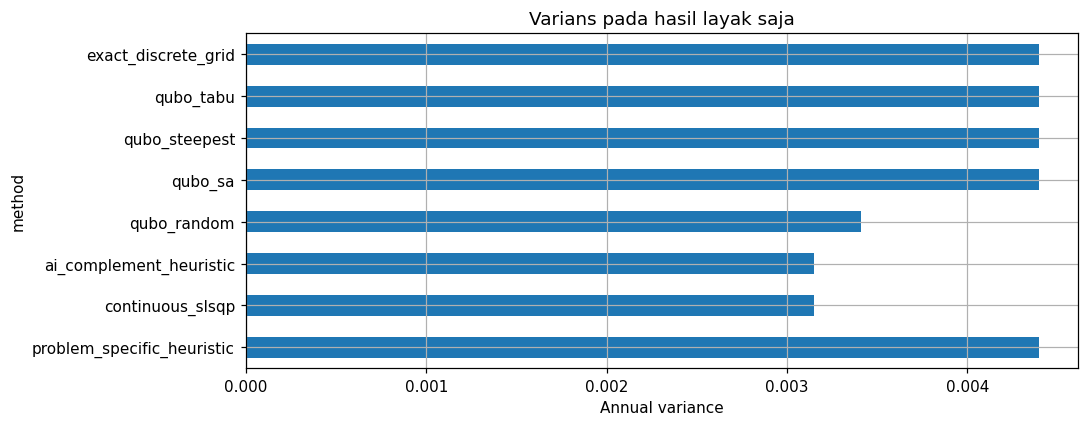

,method,realized_annual_return,realized_annual_volatility,max_drawdown,cumulative_return,evaluation
0,problem_specific_heuristic,0.020767,0.076723,-0.058195,0.012475,held-out static weights; daily rebalance; zero...
1,continuous_slsqp,0.085739,0.065150,-0.042372,0.050869,held-out static weights; daily rebalance; zero...
2,ai_complement_heuristic,0.085739,0.065150,-0.042371,0.050869,held-out static weights; daily rebalance; zero...
3,qubo_random,0.081619,0.067635,-0.041831,0.048462,held-out static weights; daily rebalance; zero...
4,qubo_sa,0.020767,0.076723,-0.058195,0.012475,held-out static weights; daily rebalance; zero...
5,qubo_steepest,0.020767,0.076723,-0.058195,0.012475,held-out static weights; daily rebalance; zero...
6,qubo_tabu,0.020767,0.076723,-0.058195,0.012475,held-out static weights; daily rebalance; zero...
7,exact_discrete_grid,0.020767,0.076723,-0.058195,0.012475,held-out static weights; daily rebalance; zero...


In [11]:
report=run_experiment(returns,seed=SEED,d=1,reads=100,sweeps=100,include_quantum=False)
table=pd.DataFrame([{k:r.get(k) for k in ['method','feasible','expected_return','variance','runtime_seconds','training_seconds']}
                    for r in report['results']])
display(table)
valid=table[table.feasible]
if len(valid):
    valid.set_index('method')['variance'].plot.barh(title='Varians pada hasil layak saja')
    plt.xlabel('Annual variance'); plt.tight_layout(); plt.show()
heldout=pd.DataFrame([{'method':r['method'],**r.get('heldout',{})} for r in report['results'] if r.get('feasible')])
display(heldout)
(artifacts/'notebook_report.json').write_text(json.dumps(report,indent=2))
print(report['periods'], report['timing_note'])

## 10. Dari notebook ke aplikasi utuh
1. Notebook menjelaskan dan menguji modul `psh/`.
2. FastAPI menerima CSV, menyimpan daily returns long-form, lalu menjalankan eksperimen yang sama.
3. PostgreSQL menyimpan dataset, provenance, report JSON dan bobot normalized dalam tabel allocations.
4. Streamlit hanya memanggil REST API; bisa diganti React kemudian tanpa mengganti algoritma.
5. GitHub Actions menguji kode dan notebook; Docker Compose menjalankan API, UI dan PostgreSQL.

Buka README.md, docs/API.md, sql/analysis.sql dan deplyment.md untuk langkah VS Code, REST/Postman, database, GitHub dan cloud.

**Kesimpulan eksperimen harus mengikuti hasil:** bila AI tidak layak atau quantum tidak mengungguli solver, catat apa adanya. Data alternatif/sintetis dan simulator tidak mereplikasi kesimpulan paper secara empiris.